In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import skew
from sklearn.cluster import DBSCAN, KMeans
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (roc_auc_score, roc_curve,
                             precision_score, recall_score, f1_score)

df = pd.read_csv('hf://datasets/maharshipandya/spotify-tracks-dataset/dataset.csv')

In [2]:
feats = ['danceability','energy','loudness','speechiness','acousticness',
         'instrumentalness','liveness','valence','tempo']
genres = ['classical','hip-hop','mandopop','metal']

d = df[df.track_genre.isin(genres)]
d = d.drop_duplicates('track_id')
d = d.drop_duplicates(subset=feats)
d = d.reset_index(drop=True)
print(len(d))

X = d[feats].to_numpy(float)
Z = (X - X.mean(0)) / X.std(0, ddof=0)
n = len(Z)
ai, ei = feats.index('acousticness'), feats.index('energy')

3408


In [3]:
def sqdist(X, C):
    d2 = (X**2).sum(1)[:,None] + (C**2).sum(1)[None,:] - 2*X@C.T
    return np.maximum(d2, 0)

def kmeans(X, C0, max_iter=20):
    C = C0.copy().astype(float)
    k = len(C)
    hist = [sqdist(X, C).min(1).sum()]
    for t in range(max_iter):
        labels = sqdist(X, C).argmin(1)
        for j in range(k):
            m = labels == j
            if m.any():
                C[j] = X[m].mean(0)
        hist.append(sqdist(X, C).min(1).sum())
    labels = sqdist(X, C).argmin(1)
    return labels, C, np.array(hist)

def init_pp(Z, k, seed):
    rng = np.random.default_rng(seed)
    idx = [rng.integers(len(Z))]
    dmin = sqdist(Z, Z[idx]).ravel()
    for _ in range(k-1):
        j = rng.choice(len(Z), p=dmin/dmin.sum())
        idx.append(j)
        dmin = np.minimum(dmin, sqdist(Z, Z[[j]]).ravel())
    return Z[idx]

def best_kmeans(X, k=4, seeds=range(10)):
    best = None
    for s in seeds:
        out = kmeans(X, init_pp(X, k, s), 20)
        if best is None or out[2][-1] < best[2][-1]:
            best = out
    return best

labZ, CZ, hZ = best_kmeans(Z)
print(hZ[-1])

15811.389037790766


In [4]:
s = np.array([1,2,3,8,9,10,25.])
mu, sig = s.mean(), s.std(ddof=0)
print(mu, sig, (25-mu)/sig)

s2 = s.reshape(-1,1)
print(np.round(-LocalOutlierFactor(n_neighbors=2).fit(s2).negative_outlier_factor_, 3))

8.285714285714286 7.591617288906527 2.201676543772821
[0.875 1.333 0.875 0.875 1.333 0.875 9.042]


In [5]:
def pdist(X):
    sq = (X**2).sum(1)
    D2 = np.maximum(sq[:,None] + sq[None,:] - 2*X@X.T, 0)
    np.fill_diagonal(D2, np.inf)
    return np.sqrt(D2)

def knn_score(X, k):
    return np.sort(pdist(X), axis=1)[:, k-1]

def lof(X, k):
    D = pdist(X)
    nn = len(X)
    idx = np.argsort(D, axis=1)[:, :k]
    dk = np.sort(D, axis=1)[:, k-1]
    dnb = D[np.arange(nn)[:,None], idx]
    reach = np.maximum(dk[idx], dnb)
    lrd = 1.0 / reach.mean(1)
    return lrd[idx].mean(1) / lrd

max abs diff: 1.0928813409805116e-10
LOF>1.5: 38  max: 2.569334186674885
                                            track_name  \
705  12 Variations on ‘La belle Françoise’ in E fla...   
344                          Sri Venkatesa Suprabhatam   
128            3 Gymnopédies: No. 1 Lent et douloureux   
469                                 Lakshmi Ashtothram   
771   2 Canons in F for 2 voices in 1, K508a: Nos. 1-2   

                                               artists track_genre    LOF  
705             Wolfgang Amadeus Mozart;Danielle Laval   classical  2.569  
344    M. S. Subbulakshmi;T. K. Murthy;V.V.Subramaniam   classical  2.140  
128                          Erik Satie;Alice Sara Ott   classical  1.992  
469                                 M. S. Subbulakshmi   classical  1.950  
771  Wolfgang Amadeus Mozart;Karl-Heinz Steffens;We...   classical  1.927  


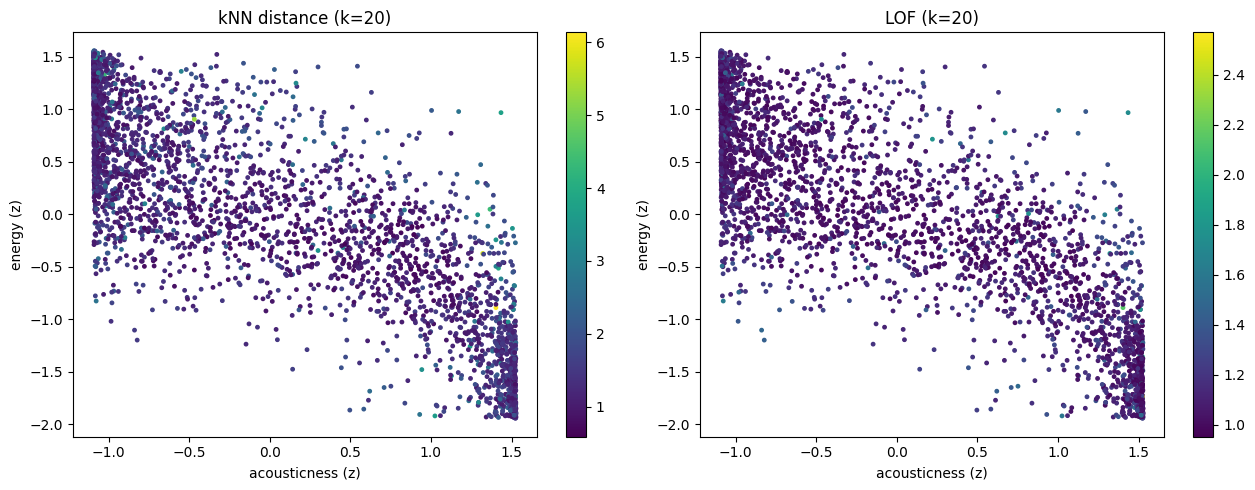

In [6]:
L = lof(Z, 20)
ref = -LocalOutlierFactor(n_neighbors=20).fit(Z).negative_outlier_factor_
print('max abs diff:', np.abs(L - ref).max())
print('LOF>1.5:', (L > 1.5).sum(), ' max:', L.max())

top5 = np.argsort(-L)[:5]
print(d.loc[top5, ['track_name','artists','track_genre']].assign(LOF=L[top5].round(3)))

K = knn_score(Z, 20)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, sc, name in zip(ax, [K, L], ['kNN distance (k=20)', 'LOF (k=20)']):
    h = a.scatter(Z[:,ai], Z[:,ei], c=sc, s=6, cmap='viridis')
    a.set_xlabel('acousticness (z)'); a.set_ylabel('energy (z)'); a.set_title(name)
    plt.colorbar(h, ax=a)
plt.tight_layout(); plt.show()

In [7]:
def cluster_score(X, lab, C):
    dist = np.sqrt(sqdist(X, C)[np.arange(len(X)), lab])
    avg = np.array([dist[lab == j].mean() for j in range(len(C))])
    return dist / avg[lab]

S_clu = cluster_score(Z, labZ, CZ)

In [8]:
db = DBSCAN(eps=2.0, min_samples=18).fit(Z)
noise = db.labels_ == -1
m = int(noise.sum())
print('clusters:', len(set(db.labels_) - {-1}), ' noise m =', m)

clusters: 1  noise m = 55


In [9]:
iso = IsolationForest(n_estimators=200, random_state=0).fit(Z)
S_if = -iso.score_samples(Z)

scores = {'kNN': K, 'LOF': L, 'Cluster': S_clu, 'IForest': S_if}
tops = {name: np.argsort(-sc)[:m] for name, sc in scores.items()}
noise_idx = set(np.where(noise)[0])
for name, t in tops.items():
    print(name, 'overlap with DBSCAN noise:', len(set(t) & noise_idx), '/', m)

kNN overlap with DBSCAN noise: 46 / 55
LOF overlap with DBSCAN noise: 24 / 55
Cluster overlap with DBSCAN noise: 33 / 55
IForest overlap with DBSCAN noise: 30 / 55


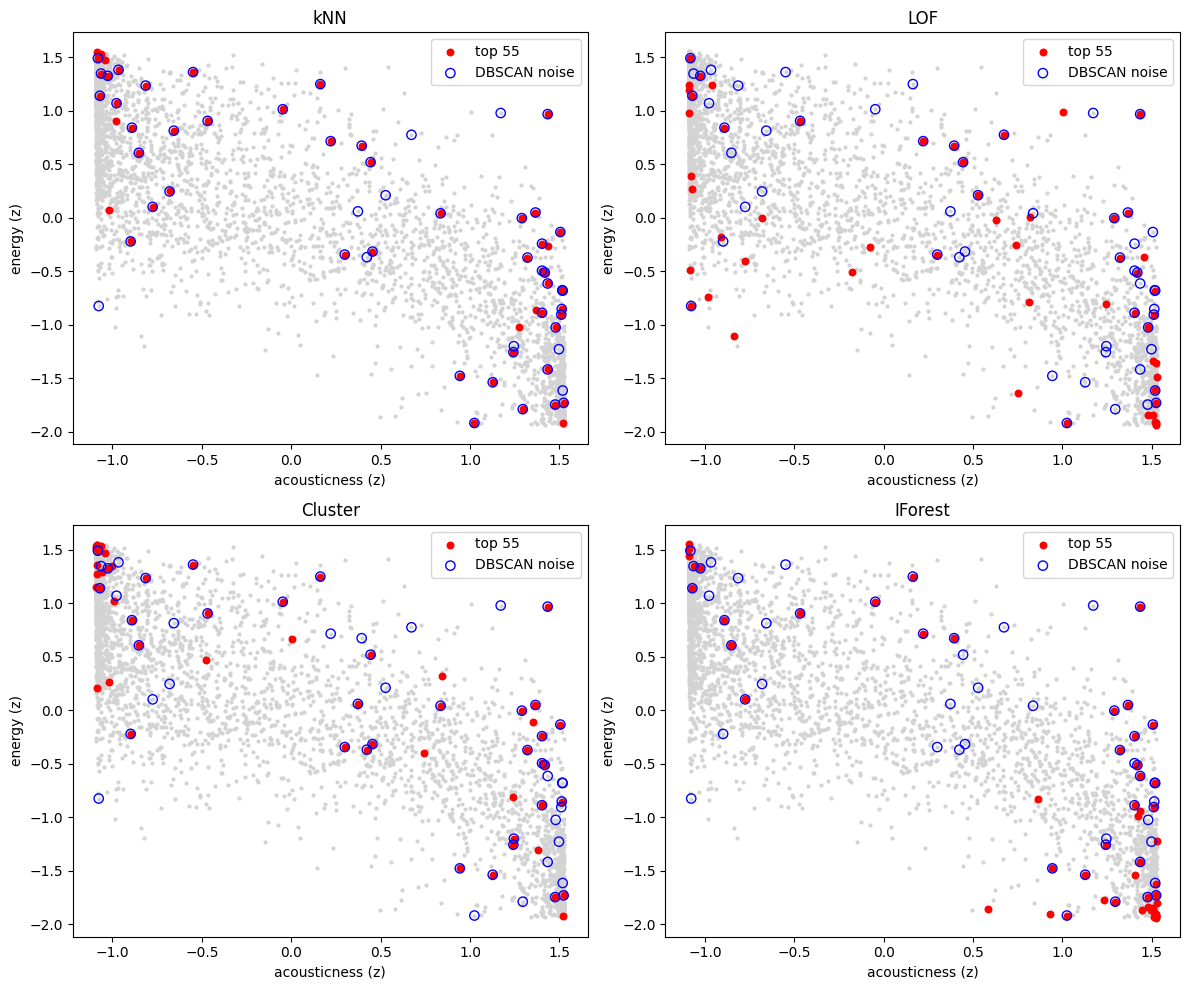

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
for a, (name, t) in zip(ax.ravel(), tops.items()):
    a.scatter(Z[:,ai], Z[:,ei], s=4, c='lightgray')
    a.scatter(Z[t,ai], Z[t,ei], s=22, c='red', label=f'top {m}')
    a.scatter(Z[noise,ai], Z[noise,ei], s=45, facecolors='none',
              edgecolors='blue', label='DBSCAN noise')
    a.set_title(name); a.set_xlabel('acousticness (z)'); a.set_ylabel('energy (z)')
    a.legend()
plt.tight_layout(); plt.show()

In [11]:
cand = np.argsort(-L)[:2]
print(d.loc[cand, ['track_name','artists','track_genre']])

                                            track_name  \
705  12 Variations on ‘La belle Françoise’ in E fla...   
344                          Sri Venkatesa Suprabhatam   

                                             artists track_genre  
705           Wolfgang Amadeus Mozart;Danielle Laval   classical  
344  M. S. Subbulakshmi;T. K. Murthy;V.V.Subramaniam   classical  


In [12]:
rng = np.random.default_rng(0)
U = rng.normal(size=(20, 9))
U /= np.linalg.norm(U, axis=1, keepdims=True)
A_glob = U * rng.uniform(4, 6, (20, 1))

rng = np.random.default_rng(1)
A_corr = np.empty((20, 9))
for j in range(9):
    A_corr[:, j] = Z[rng.integers(0, n, 20), j]

def evaluate(Xa, y):
    labA, CA, _ = best_kmeans(Xa)
    sc = {
        'kNN':     knn_score(Xa, 20),
        'LOF':     lof(Xa, 20),
        'Cluster': cluster_score(Xa, labA, CA),
        'IForest': -IsolationForest(n_estimators=200, random_state=0)
                       .fit(Xa).score_samples(Xa),
    }
    dbl = DBSCAN(eps=2.0, min_samples=18).fit(Xa).labels_ == -1
    return sc, dbl

In [13]:
results, rocs, dbscan_rows = [], {}, []
for kind, A in [('global', A_glob), ('correlation-breaking', A_corr)]:
    Xa = np.vstack([Z, A])
    y = np.r_[np.zeros(n), np.ones(20)].astype(int)
    sc, dbl = evaluate(Xa, y)
    rocs[kind] = {}
    for name, s_ in sc.items():
        auc = roc_auc_score(y, s_)
        p20 = y[np.argsort(-s_)[:20]].mean()
        results.append(dict(anomaly=kind, detector=name, AUC=round(auc, 4), P_at_20=p20))
        rocs[kind][name] = roc_curve(y, s_)[:2]
    dbscan_rows.append(dict(anomaly=kind, flagged=int(dbl.sum()),
                            precision=precision_score(y, dbl),
                            recall=recall_score(y, dbl),
                            F1=f1_score(y, dbl),
                            accuracy=(y == dbl).mean(),
                            all_normal_accuracy=(y == 0).mean()))

print(pd.DataFrame(results).to_string(index=False))
print(pd.DataFrame(dbscan_rows).round(4).to_string(index=False))

             anomaly detector    AUC  P_at_20
              global      kNN 0.9961     0.60
              global      LOF 0.9993     0.85
              global  Cluster 0.9832     0.25
              global  IForest 0.9698     0.40
correlation-breaking      kNN 0.8117     0.15
correlation-breaking      LOF 0.8886     0.30
correlation-breaking  Cluster 0.8340     0.05
correlation-breaking  IForest 0.7189     0.05
             anomaly  flagged  precision  recall     F1  accuracy  all_normal_accuracy
              global       75     0.2667     1.0 0.4211    0.9840               0.9942
correlation-breaking       59     0.0678     0.2 0.1013    0.9793               0.9942


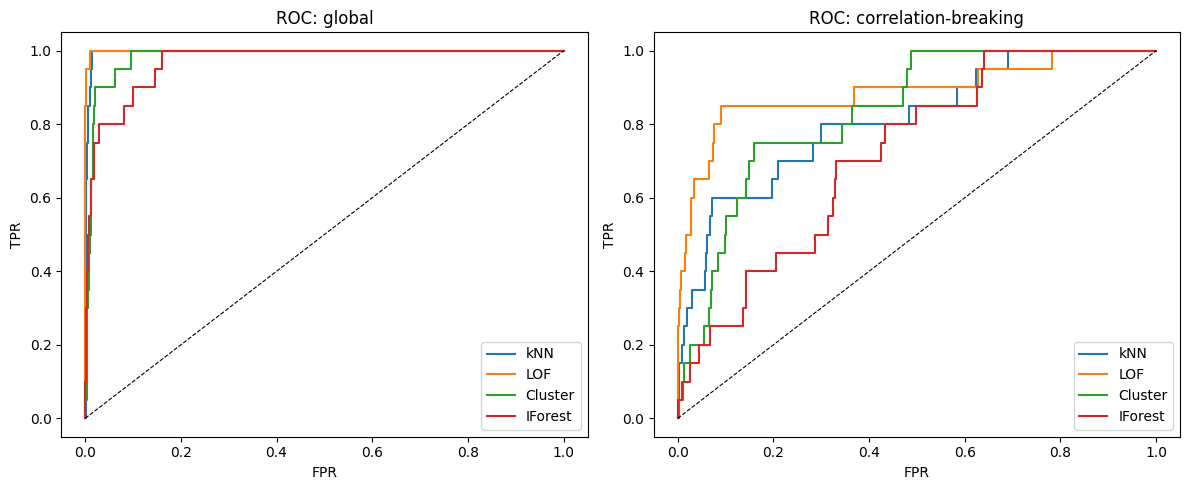

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, kind in zip(ax, rocs):
    for name, (fpr, tpr) in rocs[kind].items():
        a.plot(fpr, tpr, label=name)
    a.plot([0,1], [0,1], 'k--', lw=0.8)
    a.set_title(f'ROC: {kind}'); a.set_xlabel('FPR'); a.set_ylabel('TPR'); a.legend()
plt.tight_layout(); plt.show()